In [1]:
%reload_ext autoreload
%autoreload 2



from analysis.team_seasonranker import TeamAnalyzer as tmanalyzer
import constants.constants as constants
import seaborn as sns
from analysis.player_analyzer import PlayerAnalyzer as analyzer 
sns.set_style("whitegrid")
import visuals.radar_charts as radar
from itertools import combinations
from data.build_datasets import build_dataset

'''
Load Soccer Data
1. Load fixtures data
2. Load player match data
3. Load players data
4. Load teams data
5. Load transfers data
'''

player_dataset = build_dataset()

player_match_names = player_dataset.player_match_names
transfers = player_dataset.cleaned_transfers
fixtures = player_dataset.fixtures
players_df = player_dataset.players
teams_df = player_dataset.teams

In [2]:
ranker = tmanalyzer(fixtures)
table_ranking = ranker.rank_all_gameweeks()

In [3]:
TOP_TEAMS = 5
mask = table_ranking['gmwk_38_rank'] <= TOP_TEAMS
top_5_teams = table_ranking['team'][mask]

combos_of_2 = list(combinations(top_5_teams, 2))


In [4]:
GK_METRICS = constants.GK_METRICS
DEF_METRICS = constants.DEFENDER_METRICS
MID_METRICS = constants.MIDFIELDER_METRICS
FWD_METRICS = constants.FORWARD_METRICS

In [5]:
plyr_analysis = analyzer(player_match_names, 38)
gk_data = plyr_analysis.prepare_position_data("Goalkeeper", GK_METRICS)
def_data = plyr_analysis.prepare_position_data("Defender", DEF_METRICS)
mid_data = plyr_analysis.prepare_position_data("Midfielder", MID_METRICS)
fwd_data = plyr_analysis.prepare_position_data("Forward", FWD_METRICS)

In [6]:
top_players = {}

for team in top_5_teams:

    top_players[team] = {}
    positions = {
        "Goalkeeper": GK_METRICS,
        "Defender": DEF_METRICS,
        "Midfielder": MID_METRICS,
        "Forward": FWD_METRICS}

    for pos, metrics in positions.items():
        
        player = plyr_analysis.get_top_player(team, pos, metrics)[0]
        top_players[team][pos] = player

In [7]:
gk_player_pairs = [
    (top_players[t1]["Goalkeeper"],
     top_players[t2]["Goalkeeper"])
    for t1, t2 in combos_of_2]

def_player_pairs = [
    (top_players[t1]["Defender"],
     top_players[t2]["Defender"])
    for t1, t2 in combos_of_2]


mid_player_pairs = [
    (top_players[t1]["Midfielder"],
     top_players[t2]["Midfielder"])
    for t1, t2 in combos_of_2
]

fwd_player_pairs = [
    (top_players[t1]["Forward"],
     top_players[t2]["Forward"])
    for t1, t2 in combos_of_2
]
   

In [8]:
gk_comparison_set = plyr_analysis.build_comparison_set(gk_player_pairs, 'Goalkeeper', GK_METRICS)
def_comparison_set = plyr_analysis.build_comparison_set(def_player_pairs, 'Defender', DEF_METRICS)
mid_comparison_set = plyr_analysis.build_comparison_set(mid_player_pairs, 'Midfielder', MID_METRICS)
fwd_comparison_set = plyr_analysis.build_comparison_set(fwd_player_pairs, 'Forward', FWD_METRICS)


In [9]:
default_pairs = [
    ('#EF0107', "#D1D411"),  
    ('#EF0107', "#F1A3A3"),  
    ('#EF0107', "#0A91EC9E"),  
    ('#EF0107', "#E9AAAA"),  
    ("#F1F508", "#E95A71A0"),  
    ("#F3F709", "#0A91EC9E"),  
    ("#F4F807", "#F35F77AB"),  
    ("#F8052E", "#0A91EC9E"),  
    ('#F8052E', '#F1A3A3'),  
    ("#0A91EC9E",'#F1A3A3')   
]

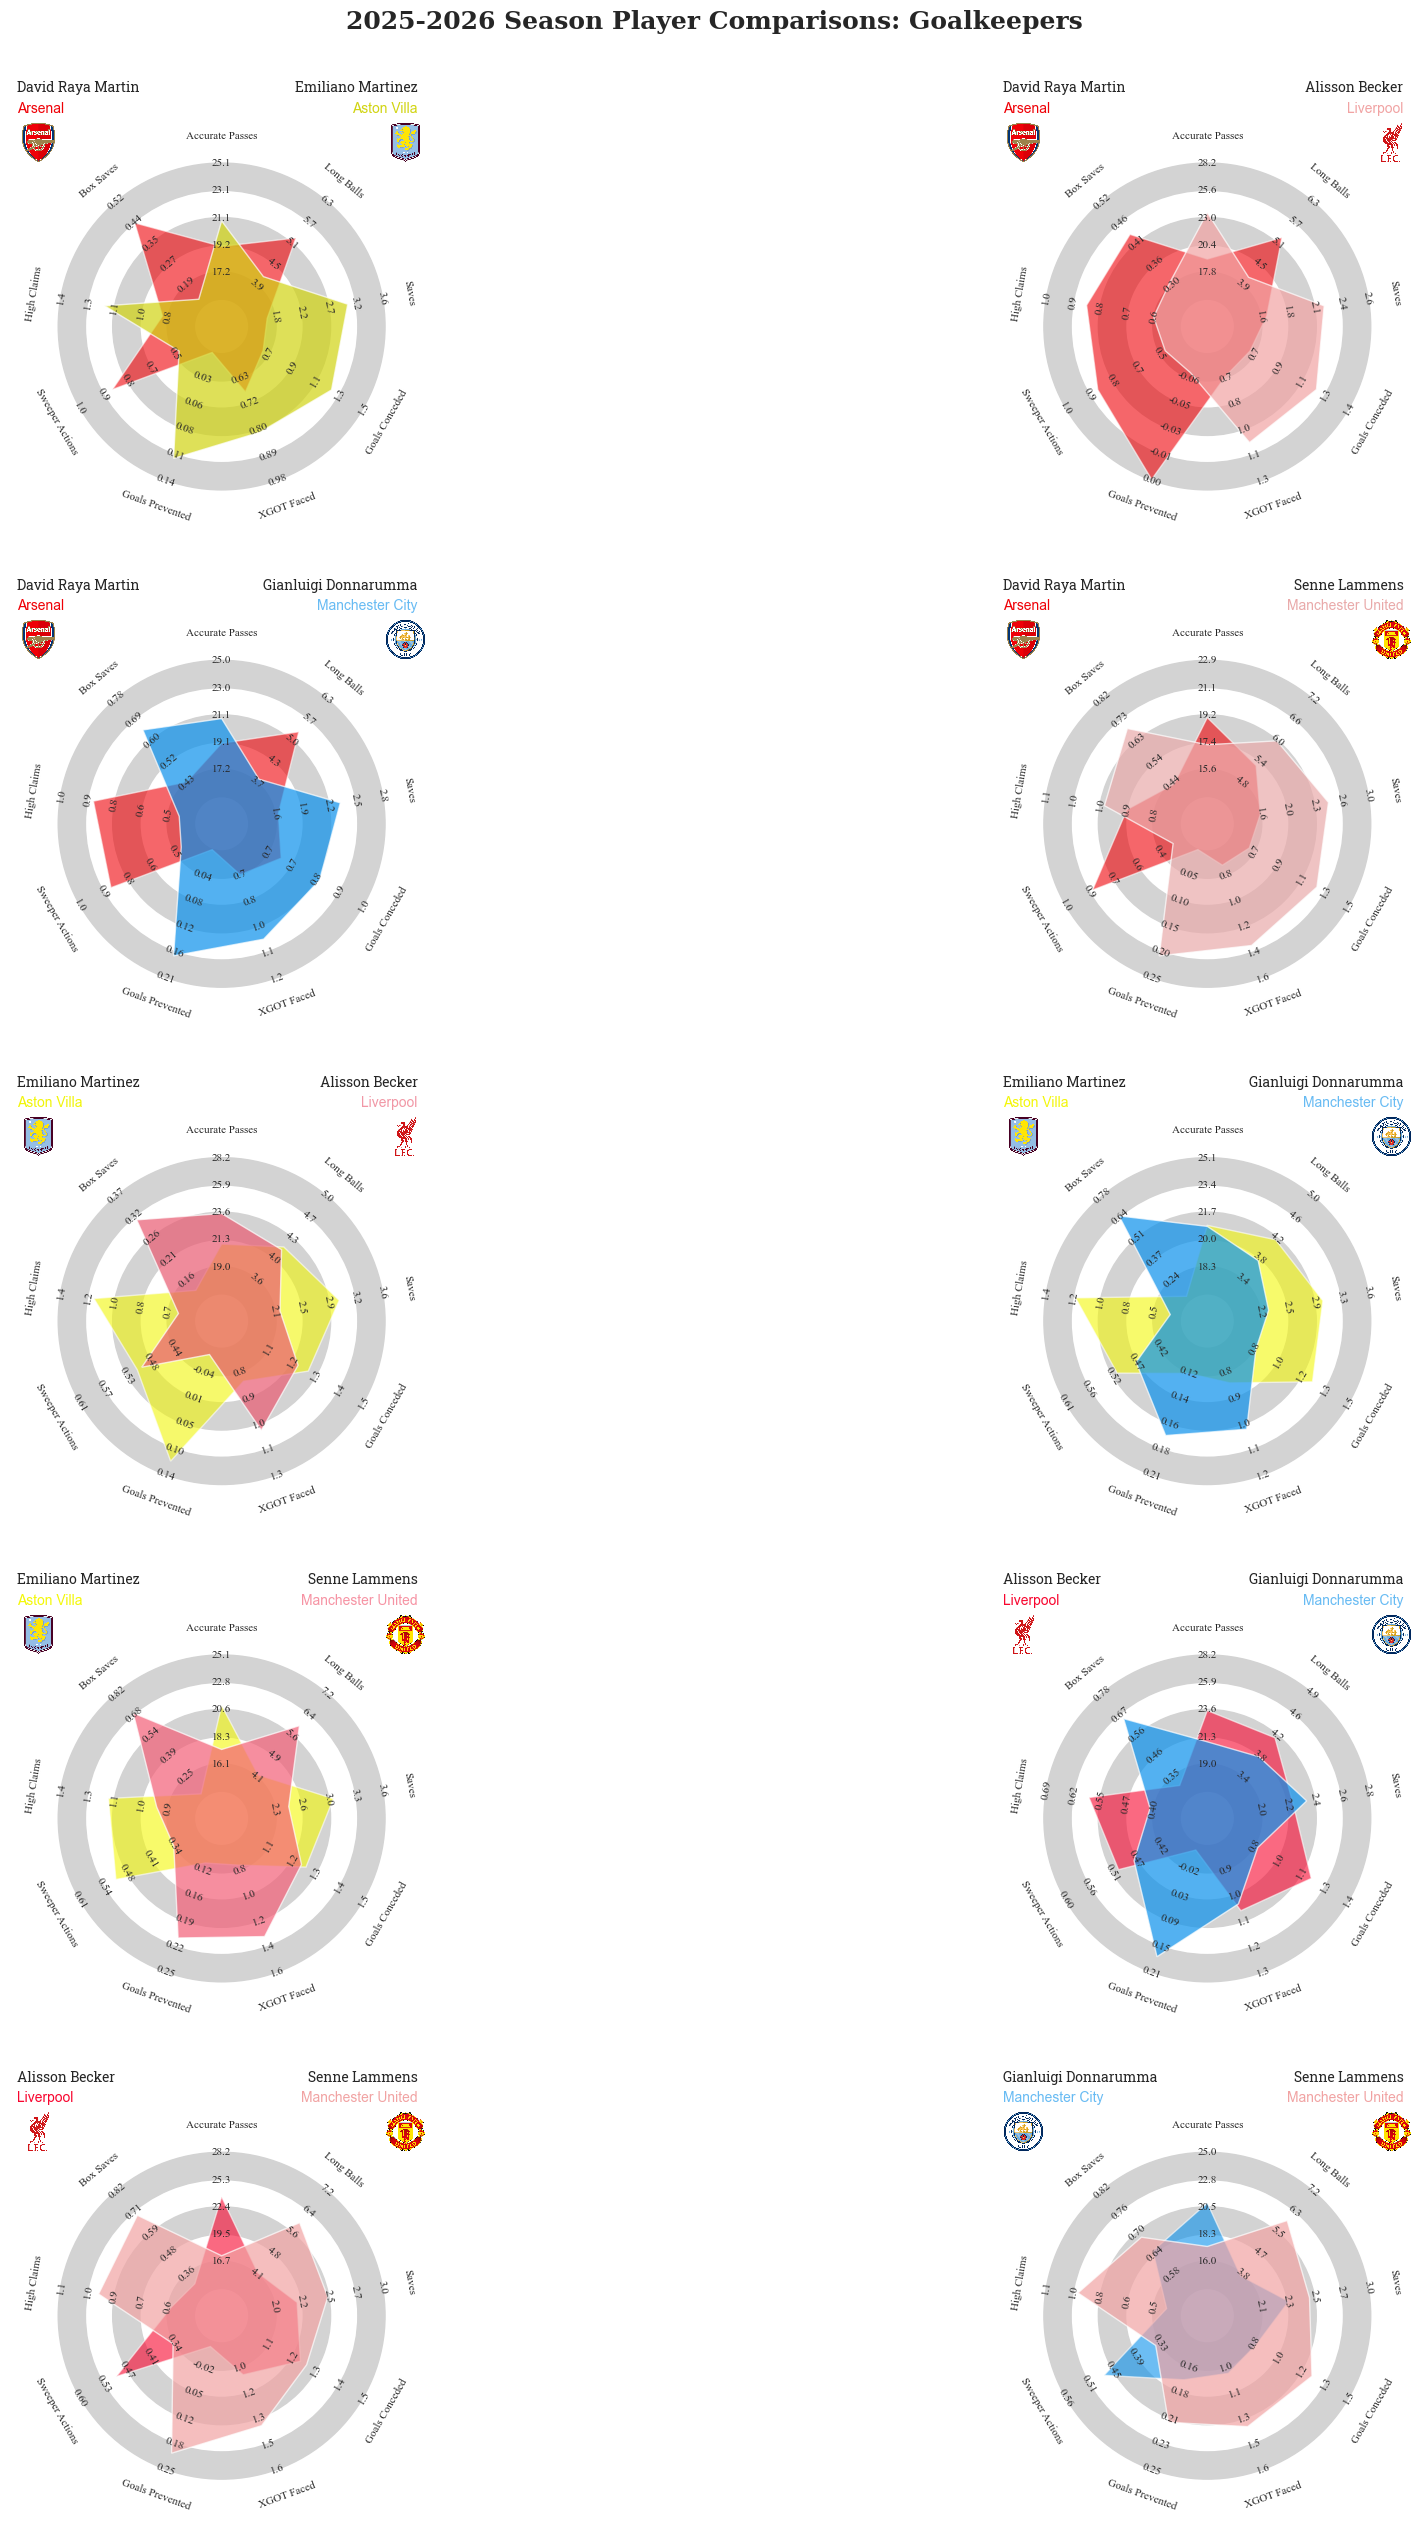

In [10]:
radar.radar_visualization(comparisons=gk_comparison_set,
                          color_pairs=default_pairs,
                          position="Goalkeeper",
                          nrows=5,
                          ncols=2,
                          figsize=(25, 25),
                          )

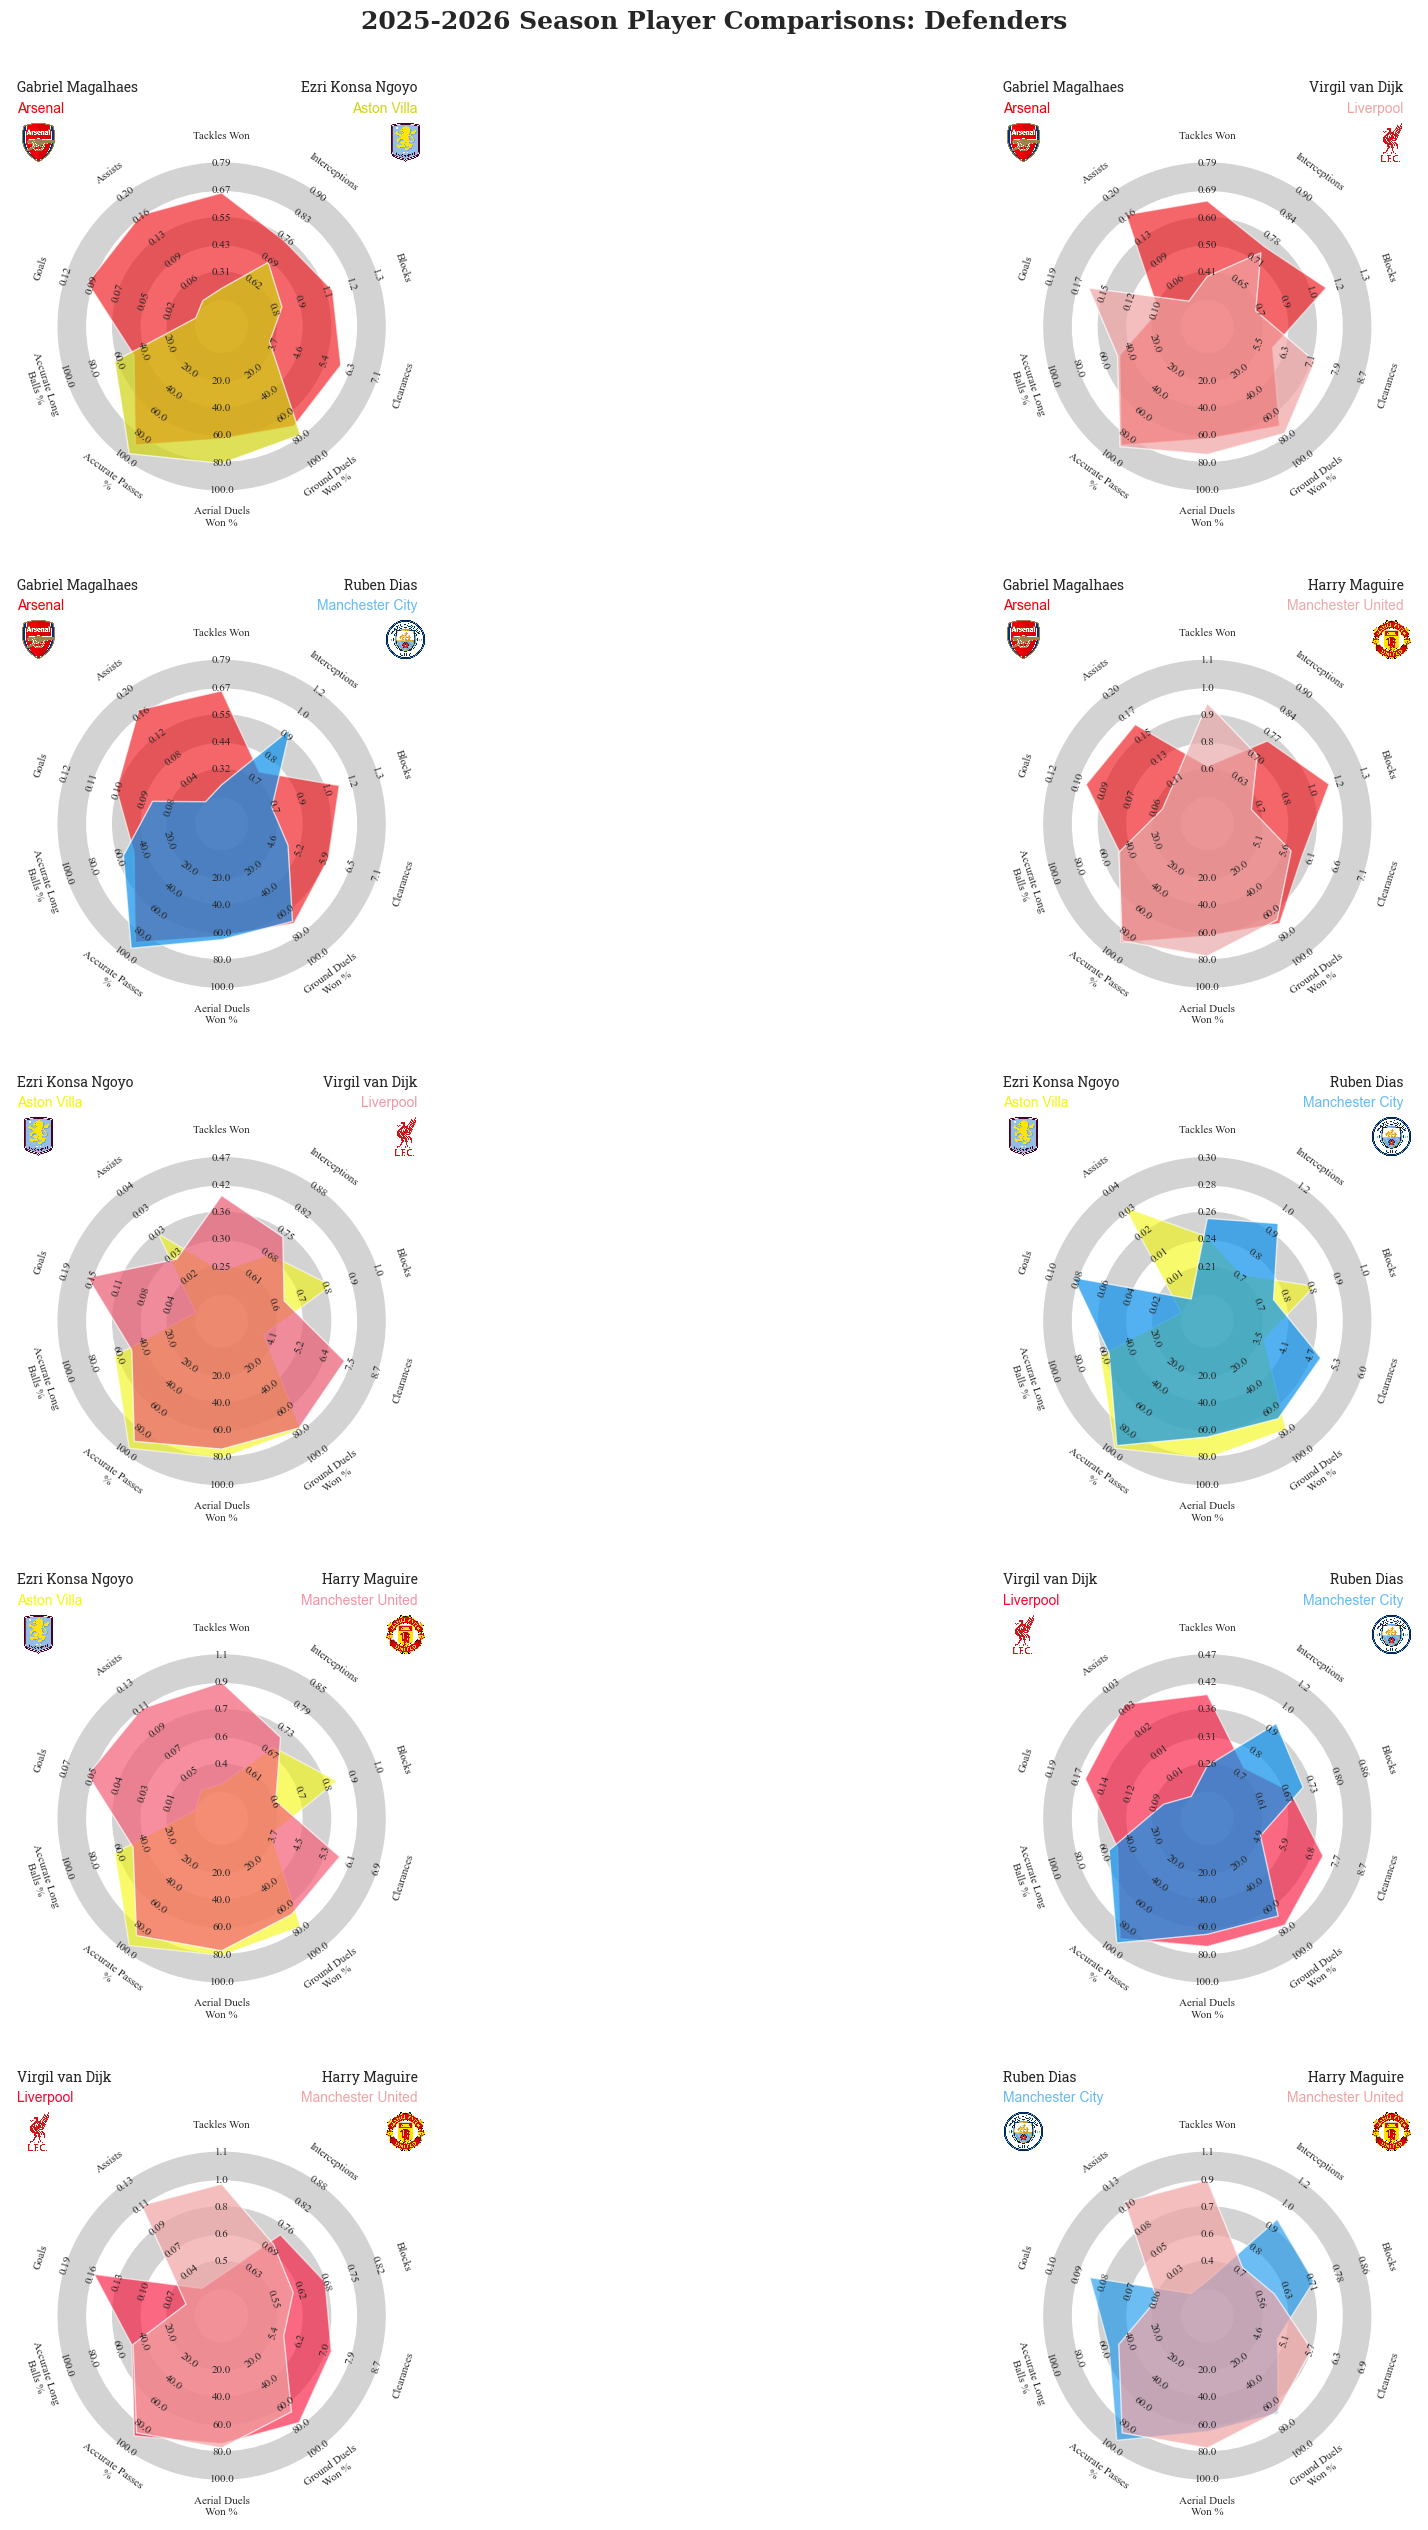

In [11]:
radar.radar_visualization(comparisons=def_comparison_set,
                          color_pairs=default_pairs,
                          position="Defender",
                          nrows=5,
                          ncols=2,
                          figsize=(25, 25),
                          )

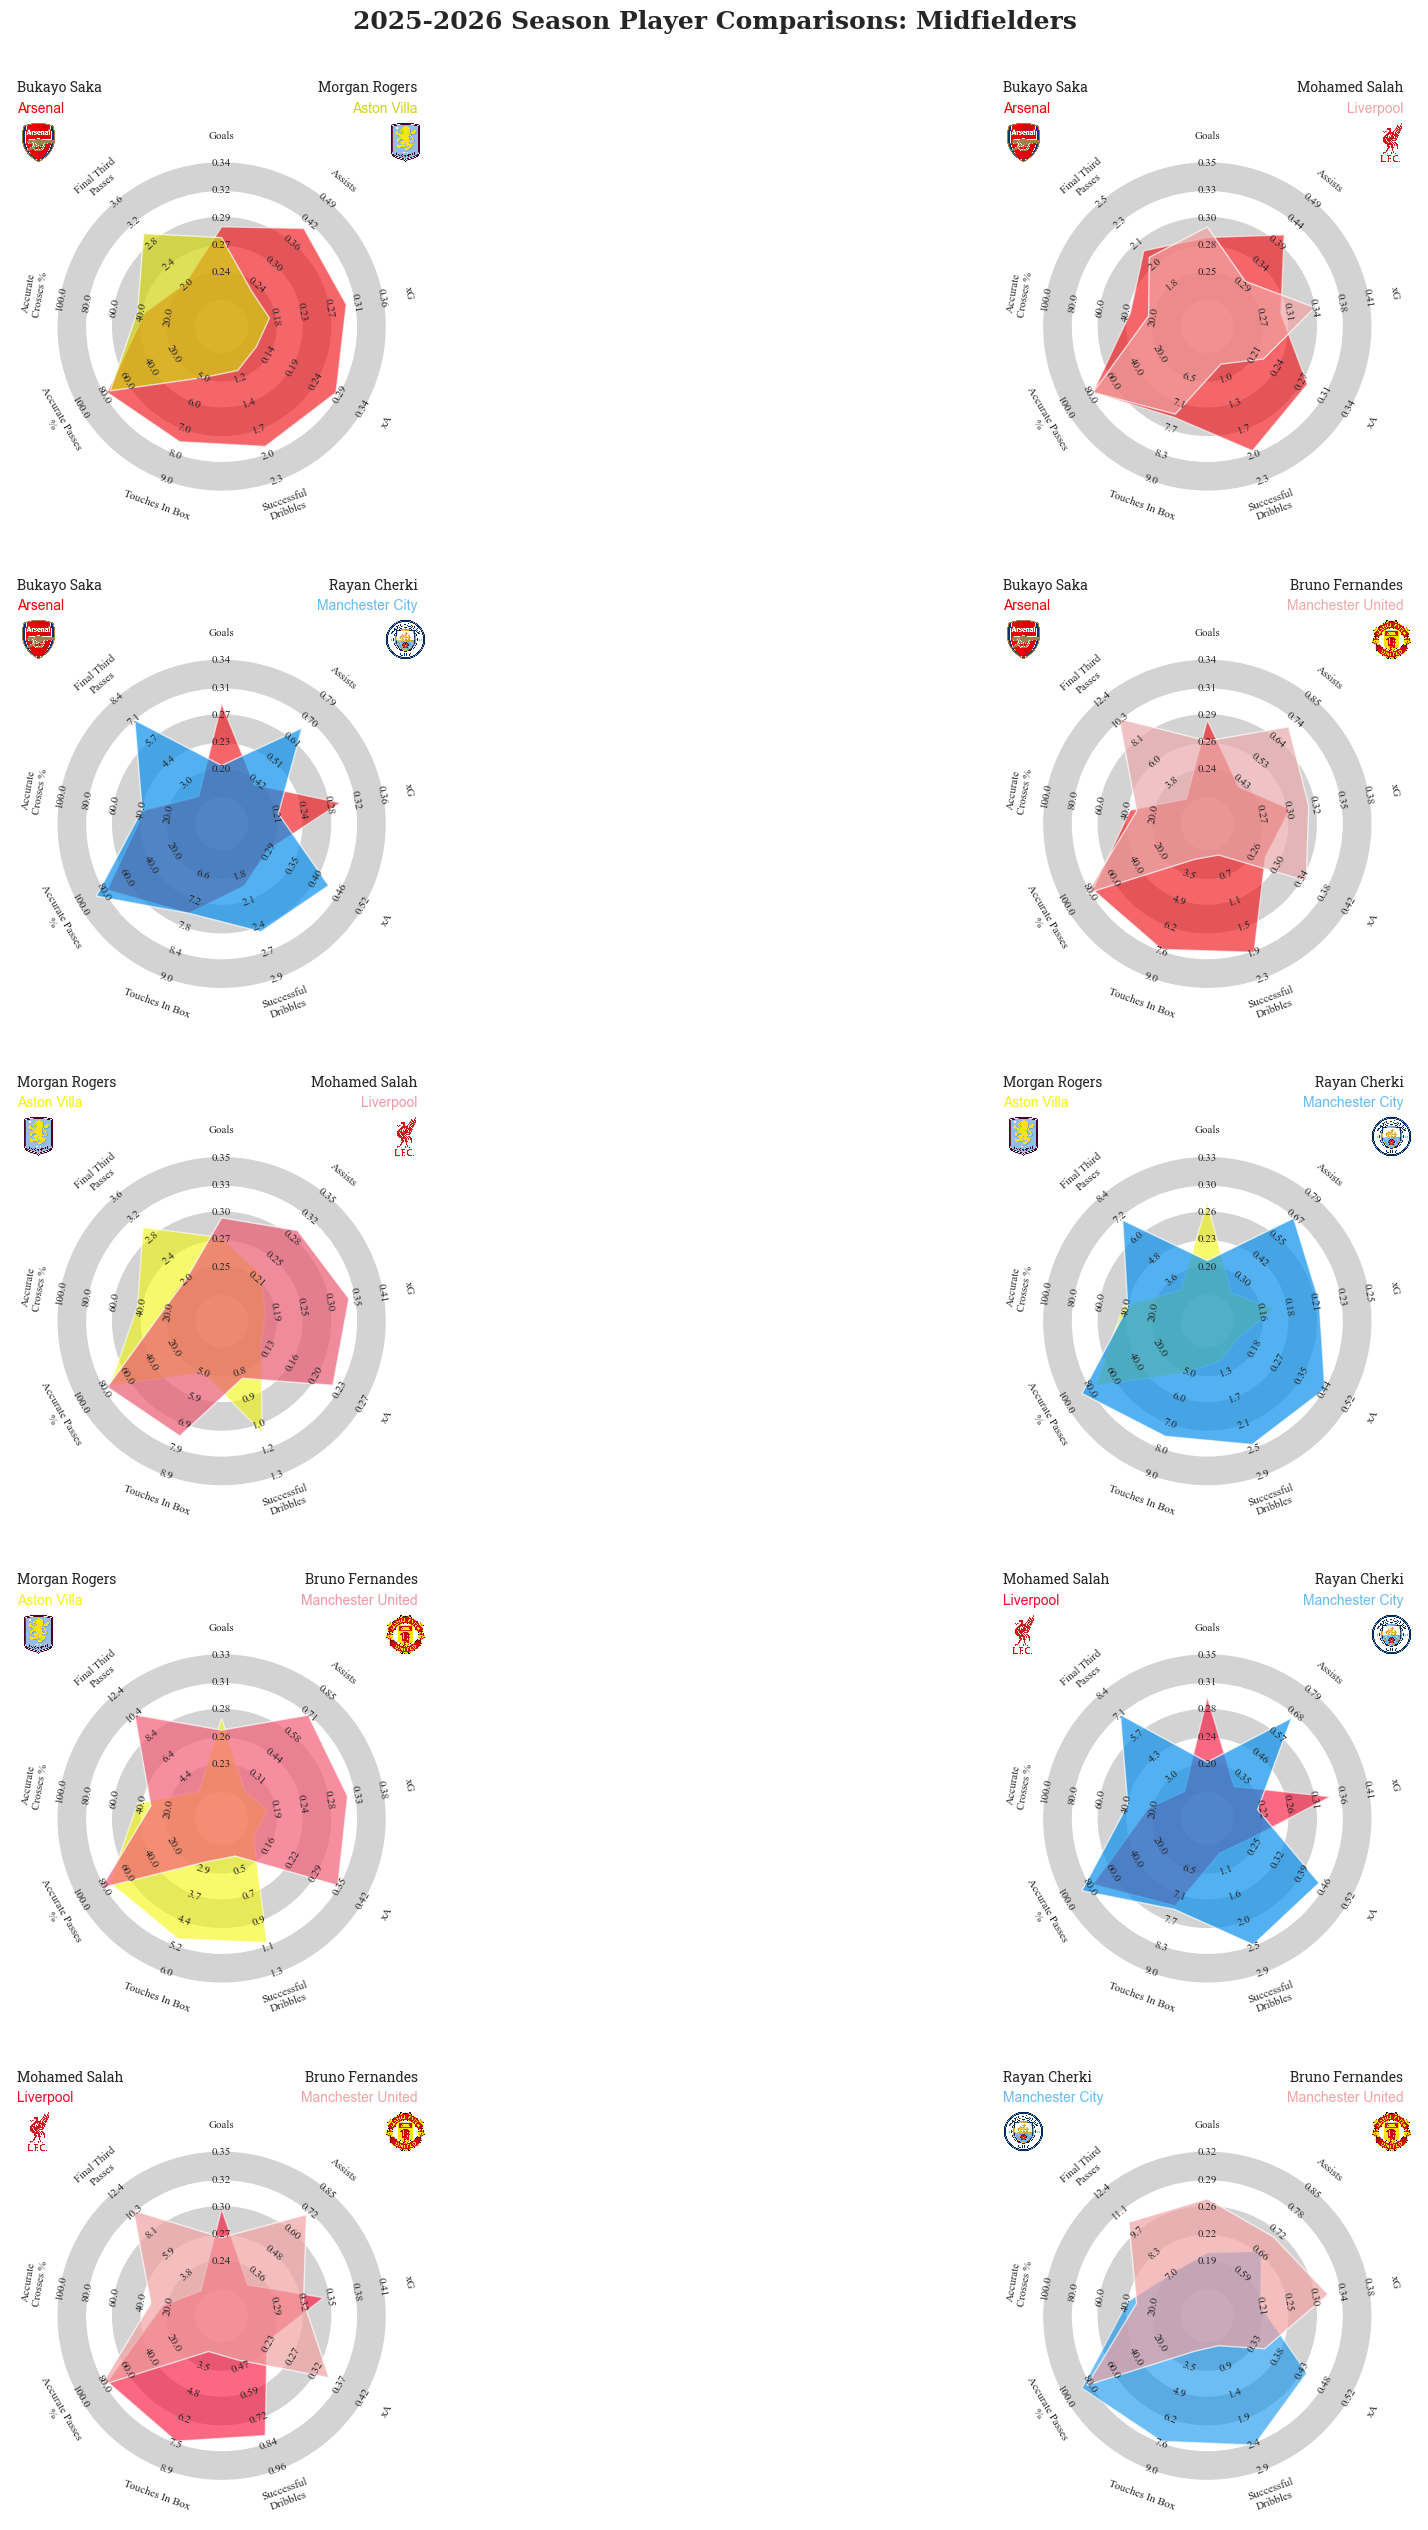

In [12]:
radar.radar_visualization(comparisons=mid_comparison_set,
                          color_pairs=default_pairs,
                          position="Midfielder",
                          nrows=5,
                          ncols=2,
                          figsize=(25, 25),
                          )

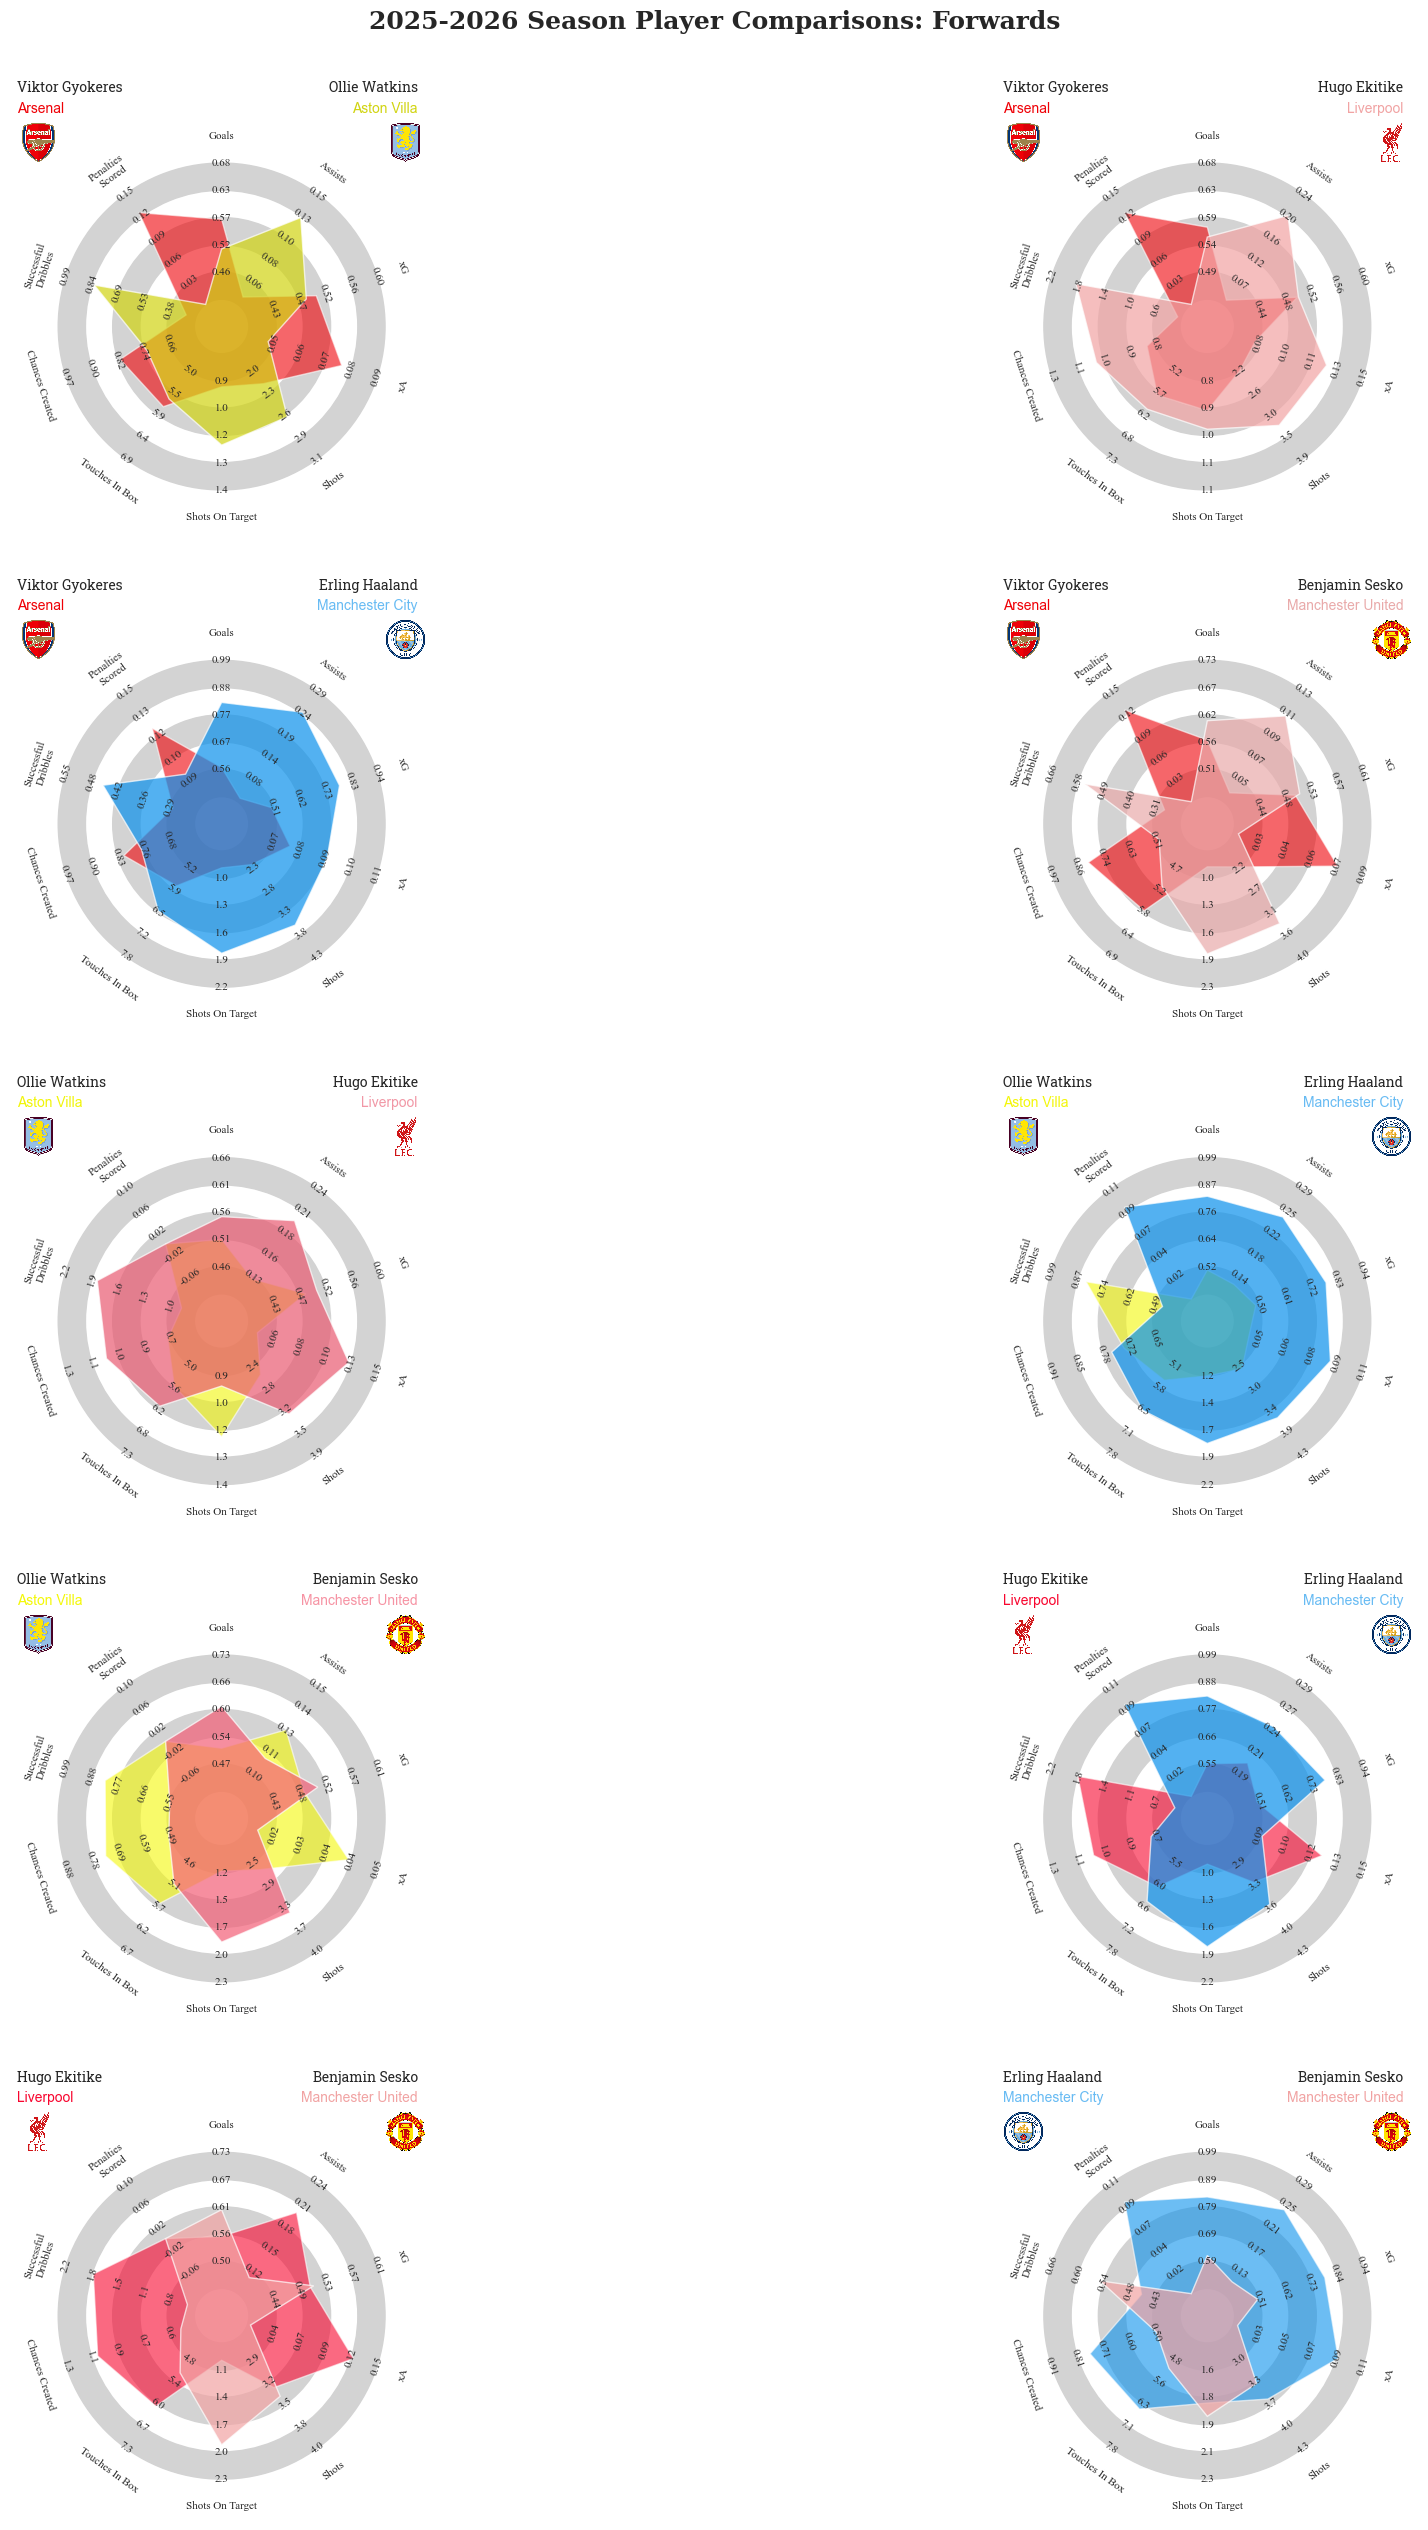

In [13]:
radar.radar_visualization(comparisons=fwd_comparison_set,
                          color_pairs=default_pairs,
                          position="Forward",
                          nrows=5,
                          ncols=2,
                          figsize=(25, 25),
                          )